# Exploratory Data Analysis of Electricity Prices

## The Economic Value of Smart EV Charging

**Market:** Germany–Luxembourg Day-Ahead Market

**Observation period:** January–December 2025

**Data source:** Fraunhofer ISE Energy-Charts API
(Bundesnetzagentur SMARD)

**Temporal resolution:** Hourly

---

## Research objective

This notebook investigates the temporal dynamics of
electricity prices to identify economic opportunities
for smart electric vehicle charging.

The analysis focuses on:

- Electricity price variability
- Seasonal and intraday price patterns
- Daily price spreads
- Timing of low-price charging opportunities

The objective is to establish the empirical market
context for the subsequent charging optimisation
and flexibility sensitivity analyses.

All analyses are based on the validated hourly dataset
generated in `00_data_ingestion.ipynb`.

No additional modifications to the underlying
electricity price observations are performed.

## 1. Environment Setup and Data Loading

The validated hourly electricity price dataset is
imported from the processed data directory.

The notebook operates independently of the data
ingestion notebook to ensure modularity and
reproducibility.

Basic integrity checks are repeated to confirm that
the imported dataset contains all 8,760 hourly
observations for 2025.

In [6]:
# Import required libraries
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Identify the project root directory
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Define project directories
processed_dir = project_root / "data" / "processed"
figures_dir = project_root / "outputs" / "figures"
tables_dir = project_root / "outputs" / "tables"

# Ensure output directories exist
figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Define validated dataset path
data_path = (
    processed_dir / "DE_LU_day_ahead_2025_hourly.csv"
)

# Load validated dataset
df_hourly = pd.read_csv(data_path)

# Restore timezone-aware timestamps
df_hourly["timestamp_utc"] = pd.to_datetime(
    df_hourly["timestamp_utc"],
    utc=True
)

df_hourly["timestamp_local"] = (
    df_hourly["timestamp_utc"]
    .dt.tz_convert("Europe/Berlin")
)

# Sort chronologically
df_hourly = (
    df_hourly
    .sort_values("timestamp_utc")
    .reset_index(drop=True)
)

# Repeat basic integrity checks
assert len(df_hourly) == 8760
assert df_hourly.isna().sum().sum() == 0
assert df_hourly["timestamp_utc"].is_unique
assert df_hourly["timestamp_utc"].is_monotonic_increasing
assert np.isfinite(df_hourly["price_eur_mwh"]).all()

assert np.allclose(
    df_hourly["price_eur_kwh"],
    df_hourly["price_eur_mwh"] / 1000
)

# Display confirmation
print("Dataset successfully loaded.")
print("Observations:", len(df_hourly))
print("First timestamp:", df_hourly["timestamp_local"].min())
print("Last timestamp:", df_hourly["timestamp_local"].max())
print("All integrity checks passed.")

display(df_hourly.head())

Dataset successfully loaded.
Observations: 8760
First timestamp: 2025-01-01 00:00:00+01:00
Last timestamp: 2025-12-31 23:00:00+01:00
All integrity checks passed.


,timestamp_utc,price_eur_mwh,source_observations,timestamp_local,price_eur_kwh
0,2024-12-31 23:00:00+00:00,2.16,1,2025-01-01 00:00:00+01:00,0.00216
1,2025-01-01 00:00:00+00:00,1.60,1,2025-01-01 01:00:00+01:00,0.00160
2,2025-01-01 01:00:00+00:00,0.00,1,2025-01-01 02:00:00+01:00,0.00000
3,2025-01-01 02:00:00+00:00,-0.01,1,2025-01-01 03:00:00+01:00,-0.00001
4,2025-01-01 03:00:00+00:00,-0.01,1,2025-01-01 04:00:00+01:00,-0.00001


## 2. Preparation of Analytical Variables

Temporal variables are derived from German local
timestamps to investigate electricity price patterns
across different hours, days, months and seasons.

Meteorological seasons are defined as follows:

| Season | Months |
|--------|--------|
| Winter | December, January, February |
| Spring | March, April, May |
| Summer | June, July, August |
| Autumn | September, October, November |

A separate analytical DataFrame is created to
preserve the original validated dataset.

In [7]:
# Create separate analytical dataset
eda = df_hourly.copy()

# Extract temporal characteristics
eda["date"] = eda["timestamp_local"].dt.date
eda["hour"] = eda["timestamp_local"].dt.hour
eda["month"] = eda["timestamp_local"].dt.month
eda["weekday"] = eda["timestamp_local"].dt.dayofweek
eda["quarter"] = eda["timestamp_local"].dt.quarter

# Distinguish weekdays and weekends
eda["is_weekend"] = eda["weekday"] >= 5

eda["day_type"] = np.where(
    eda["is_weekend"],
    "Weekend",
    "Weekday"
)

# Define meteorological seasons
season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}

eda["season"] = eda["month"].map(season_mapping)

# Define season order
season_order = [
    "Winter",
    "Spring",
    "Summer",
    "Autumn"
]

eda["season"] = pd.Categorical(
    eda["season"],
    categories=season_order,
    ordered=True
)

# Create month labels
month_order = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

eda["month_name"] = eda["month"].map(
    dict(enumerate(month_order, start=1))
)

eda["month_name"] = pd.Categorical(
    eda["month_name"],
    categories=month_order,
    ordered=True
)

# Verify analytical dataset
assert len(eda) == 8760
assert eda["season"].notna().all()

print("Analytical variables successfully created.")
print("Observations:", len(eda))

display(eda.head())

Analytical variables successfully created.
Observations: 8760


/var/folders/xc/v09c66cx1rb50f6bqk87k7th0000gn/T/ipykernel_72911/2155884286.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  eda["weekday"] = eda["timestamp_local"].dt.dayofweek


,timestamp_utc,price_eur_mwh,source_observations,timestamp_local,price_eur_kwh,date,hour,month,weekday,quarter,is_weekend,day_type,season,month_name
0,2024-12-31 23:00:00+00:00,2.16,1,2025-01-01 00:00:00+01:00,0.00216,2025-01-01,0,1,2,1,False,Weekday,Winter,Jan
1,2025-01-01 00:00:00+00:00,1.60,1,2025-01-01 01:00:00+01:00,0.00160,2025-01-01,1,1,2,1,False,Weekday,Winter,Jan
2,2025-01-01 01:00:00+00:00,0.00,1,2025-01-01 02:00:00+01:00,0.00000,2025-01-01,2,1,2,1,False,Weekday,Winter,Jan
3,2025-01-01 02:00:00+00:00,-0.01,1,2025-01-01 03:00:00+01:00,-0.00001,2025-01-01,3,1,2,1,False,Weekday,Winter,Jan
4,2025-01-01 03:00:00+00:00,-0.01,1,2025-01-01 04:00:00+01:00,-0.00001,2025-01-01,4,1,2,1,False,Weekday,Winter,Jan


## 3. Visualisation Settings

A consistent graphical style is applied to ensure
clarity and comparability across all figures.

Figures are exported in PNG and PDF formats.
Vector-based PDF files are suitable for inclusion
in the final LaTeX reflection paper.

In [8]:
# Define graphical style
sns.set_theme(
    style="whitegrid",
    palette="colorblind"
)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.2,
    "pdf.fonttype": 42
})

# Define consistent seasonal colours
season_colors = dict(
    zip(
        season_order,
        sns.color_palette("colorblind", 4)
    )
)

# Define reusable figure export function
def save_figure(fig, filename):

    """Export a figure in PNG and vector PDF formats."""

    for extension in ["png", "pdf"]:

        fig.savefig(
            figures_dir / f"{filename}.{extension}",
            bbox_inches="tight"
        )

print("Visualisation settings configured.")

Visualisation settings configured.


## 4. Annual Electricity Price Evolution

Electricity price variability creates opportunities
for intertemporal substitution of consumption.

This section examines the evolution of German–
Luxembourg day-ahead electricity prices throughout
2025, comparing hourly observations with daily and
annual average prices.

The analysis establishes the empirical market context
within which smart EV charging can generate economic
value.

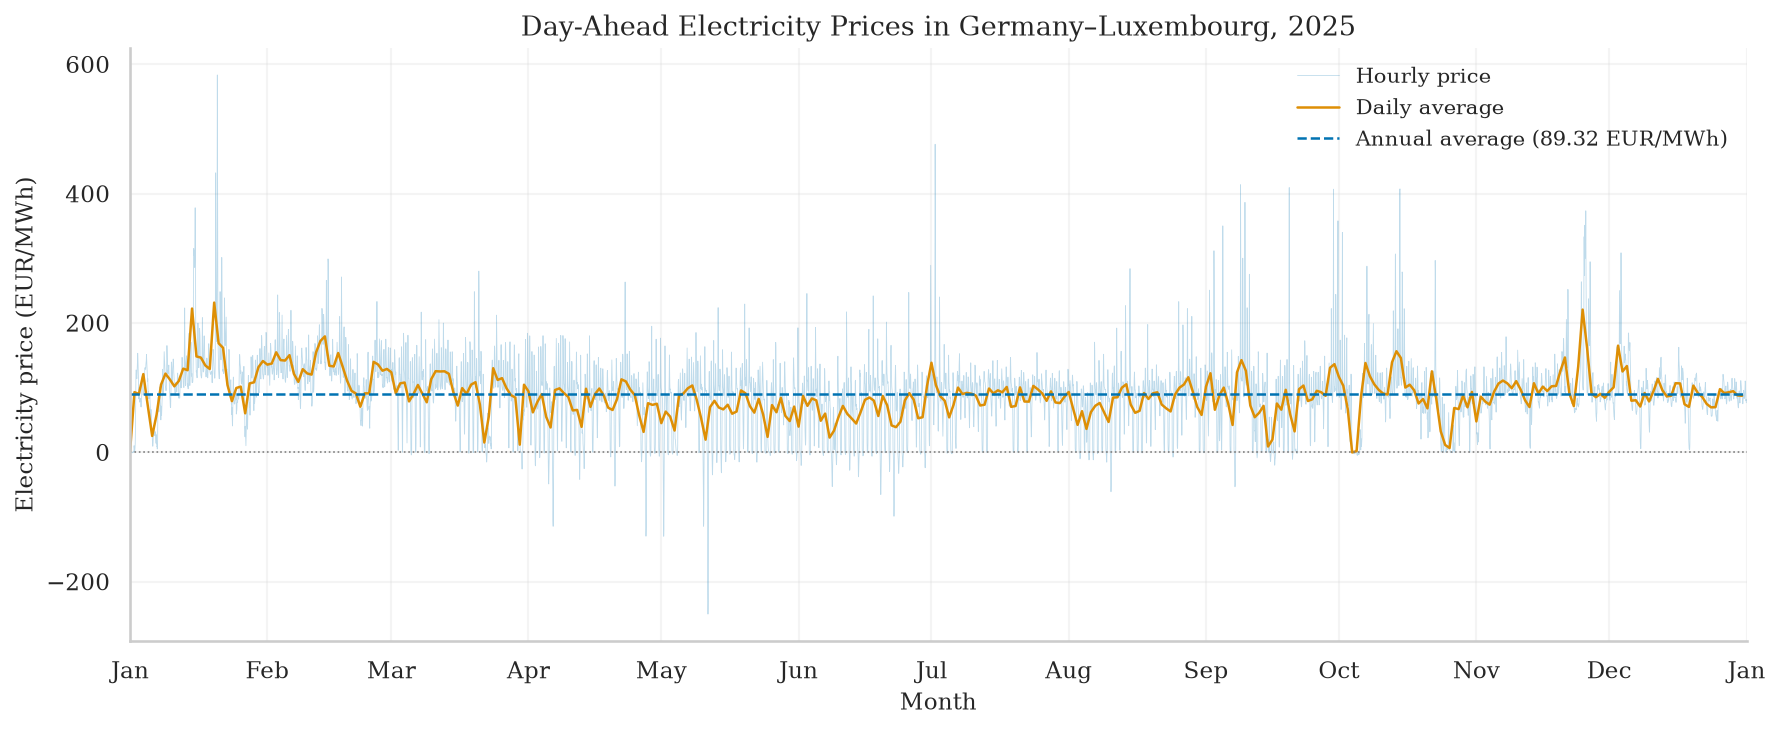

In [9]:
# Calculate daily average electricity prices
daily_prices = (
    eda
    .groupby("date")["price_eur_mwh"]
    .mean()
)

# Restore local timestamps
daily_prices.index = (
    pd.to_datetime(daily_prices.index)
    .tz_localize("Europe/Berlin")
)

# Calculate annual mean
annual_mean = eda["price_eur_mwh"].mean()

# Create figure
fig, ax = plt.subplots(figsize=(12, 5))

# Hourly electricity prices
ax.plot(
    eda["timestamp_local"],
    eda["price_eur_mwh"],
    linewidth=0.4,
    alpha=0.25,
    label="Hourly price"
)

# Daily average electricity prices
ax.plot(
    daily_prices.index,
    daily_prices.values,
    linewidth=1.2,
    label="Daily average"
)

# Annual mean
ax.axhline(
    annual_mean,
    linestyle="--",
    linewidth=1.2,
    label=f"Annual average ({annual_mean:.2f} EUR/MWh)"
)

# Zero-price reference
ax.axhline(
    0,
    linewidth=0.8,
    linestyle=":",
    color="grey"
)

# Labels
ax.set_title(
    "Day-Ahead Electricity Prices in Germany–Luxembourg, 2025"
)

ax.set_xlabel("Month")
ax.set_ylabel("Electricity price (EUR/MWh)")

# Format monthly axis
ax.xaxis.set_major_locator(
    mdates.MonthLocator(tz="Europe/Berlin")
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b", tz="Europe/Berlin")
)

ax.set_xlim(
    pd.Timestamp("2025-01-01", tz="Europe/Berlin"),
    pd.Timestamp("2026-01-01", tz="Europe/Berlin")
)

ax.legend(frameon=False)

fig.tight_layout()

# Export figure
save_figure(fig, "01_annual_price_evolution")

plt.show()

#### 4.1 Descriptive statisics

In [10]:
prices = eda["price_eur_mwh"]

annual_summary = pd.Series({
    "Total hourly observations": len(prices),
    "Mean price (EUR/MWh)": prices.mean(),
    "Median price (EUR/MWh)": prices.median(),
    "Standard deviation (EUR/MWh)": prices.std(),
    "Minimum price (EUR/MWh)": prices.min(),
    "Maximum price (EUR/MWh)": prices.max(),
    "25th percentile (EUR/MWh)": prices.quantile(0.25),
    "75th percentile (EUR/MWh)": prices.quantile(0.75),
    "Negative-price hours (unrounded)": (prices < 0).sum(),
    "Negative-price hours (2 decimals)": (
        prices.round(2) < 0
    ).sum(),
    "Negative-price share (%)": (
        (prices < 0).mean() * 100
    )
}, name="Value")

display(annual_summary.to_frame().round(4))

# Export statistics
annual_summary.to_csv(
    tables_dir / "annual_price_summary.csv",
    header=True
)

,Value
Total hourly observations,8760.0000
Mean price (EUR/MWh),89.3217
Median price (EUR/MWh),92.4300
Standard deviation (EUR/MWh),52.1015
Minimum price (EUR/MWh),-250.3200
Maximum price (EUR/MWh),583.4000
25th percentile (EUR/MWh),71.0875
75th percentile (EUR/MWh),114.1425
Negative-price hours (unrounded),576.0000
Negative-price hours (2 decimals),573.0000


## 5. Seasonal Hourly Electricity Price Profiles

The economic value of smart charging depends not
only on electricity price variability but also on
the temporal availability of low-price periods.

Average hourly electricity prices are calculated
separately for each meteorological season.

This analysis investigates whether economically
attractive charging periods differ across seasons,
providing a basis for assessing the limitations of
fixed-time charging strategies.

The resulting profiles represent seasonal average
prices rather than actual individual charging sessions.

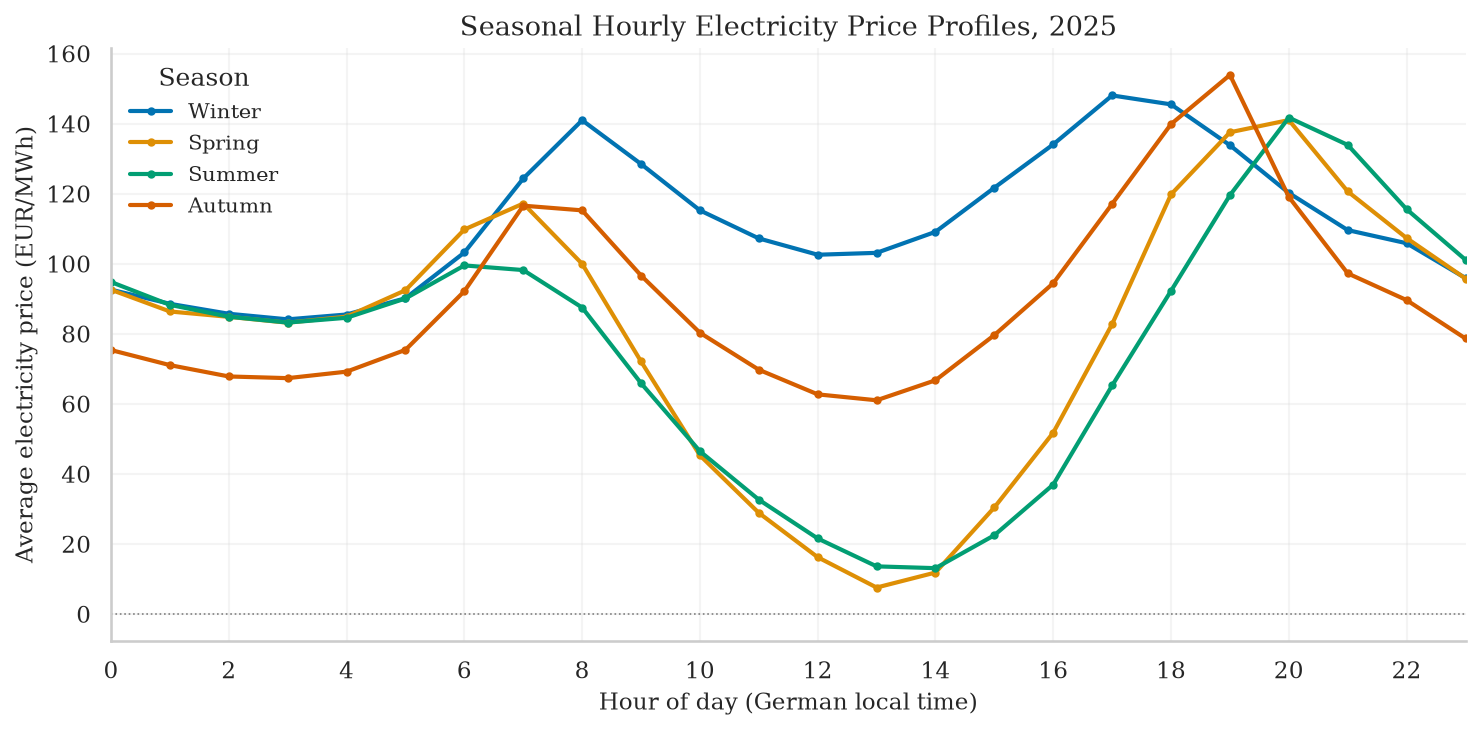

In [11]:
# Calculate seasonal average hourly prices
seasonal_profiles = (
    eda
    .groupby(
        ["season", "hour"],
        observed=True
    )["price_eur_mwh"]
    .mean()
    .unstack("season")
)

# Ensure consistent season order
seasonal_profiles = seasonal_profiles[season_order]

# Create figure
fig, ax = plt.subplots(figsize=(10, 5))

for season in season_order:

    ax.plot(
        seasonal_profiles.index,
        seasonal_profiles[season],
        color=season_colors[season],
        marker="o",
        markersize=3,
        linewidth=2,
        label=season
    )

# Zero-price reference
ax.axhline(
    0,
    linestyle=":",
    linewidth=0.8,
    color="grey"
)

# Labels
ax.set_title(
    "Seasonal Hourly Electricity Price Profiles, 2025"
)

ax.set_xlabel("Hour of day (German local time)")
ax.set_ylabel("Average electricity price (EUR/MWh)")

ax.set_xticks(range(0, 24, 2))
ax.set_xlim(0, 23)

ax.legend(
    title="Season",
    frameon=False
)

fig.tight_layout()

# Export figure
save_figure(fig, "02_seasonal_hourly_profiles")

plt.show()

#### 5.1 Quantify seasonal price differences

In [12]:
# Construct seasonal summary table
seasonal_summary = pd.DataFrame({
    "Cheapest hour": seasonal_profiles.idxmin(),
    "Lowest average price (EUR/MWh)": (
        seasonal_profiles.min()
    ),
    "Most expensive hour": seasonal_profiles.idxmax(),
    "Highest average price (EUR/MWh)": (
        seasonal_profiles.max()
    )
})

# Calculate average profile price spreads
seasonal_summary["Profile spread (EUR/MWh)"] = (
    seasonal_summary["Highest average price (EUR/MWh)"]
    - seasonal_summary["Lowest average price (EUR/MWh)"]
)

# Convert spreads into cents per kWh
seasonal_summary["Profile spread (ct/kWh)"] = (
    seasonal_summary["Profile spread (EUR/MWh)"] / 10
)

# Display results
display(seasonal_summary.round(2))

# Export underlying data and summary
seasonal_profiles.to_csv(
    tables_dir / "seasonal_hourly_profiles.csv"
)

seasonal_summary.to_csv(
    tables_dir / "seasonal_price_summary.csv"
)

,Cheapest hour,Lowest average price (EUR/MWh),Most expensive hour,Highest average price (EUR/MWh),Profile spread (EUR/MWh),Profile spread (ct/kWh)
season,,,,,,
Winter,3,84.14,17,148.05,63.92,6.39
Spring,13,7.58,20,141.02,133.45,13.34
Summer,14,13.11,20,141.73,128.62,12.86
Autumn,13,61.03,19,153.90,92.87,9.29


## 6. Monthly Electricity Price Distributions

This section investigates the distribution of hourly
electricity prices across individual months.

Monthly boxplots illustrate differences in median prices,
dispersion, interquartile ranges and extreme observations.

The objective is to assess whether seasonal average
profiles conceal substantial variation in electricity
market conditions.

,count,mean,median,std,min,max,Negative-price hours
month_name,,,,,,,
Jan,744,114.14,114.92,59.92,-1.01,583.40,14
Feb,672,128.52,127.02,36.17,37.10,298.91,0
Mar,743,94.73,101.91,49.21,-26.07,280.07,30
Apr,720,77.94,88.40,50.15,-129.81,263.20,75
May,744,67.34,85.32,55.69,-250.32,229.11,129
Jun,720,63.99,76.72,54.56,-99.01,288.97,141
Jul,744,87.80,92.49,39.44,-2.26,476.19,12
Aug,744,76.99,88.66,45.63,-61.08,283.89,64
Sep,720,83.51,86.10,59.41,-53.40,413.66,60


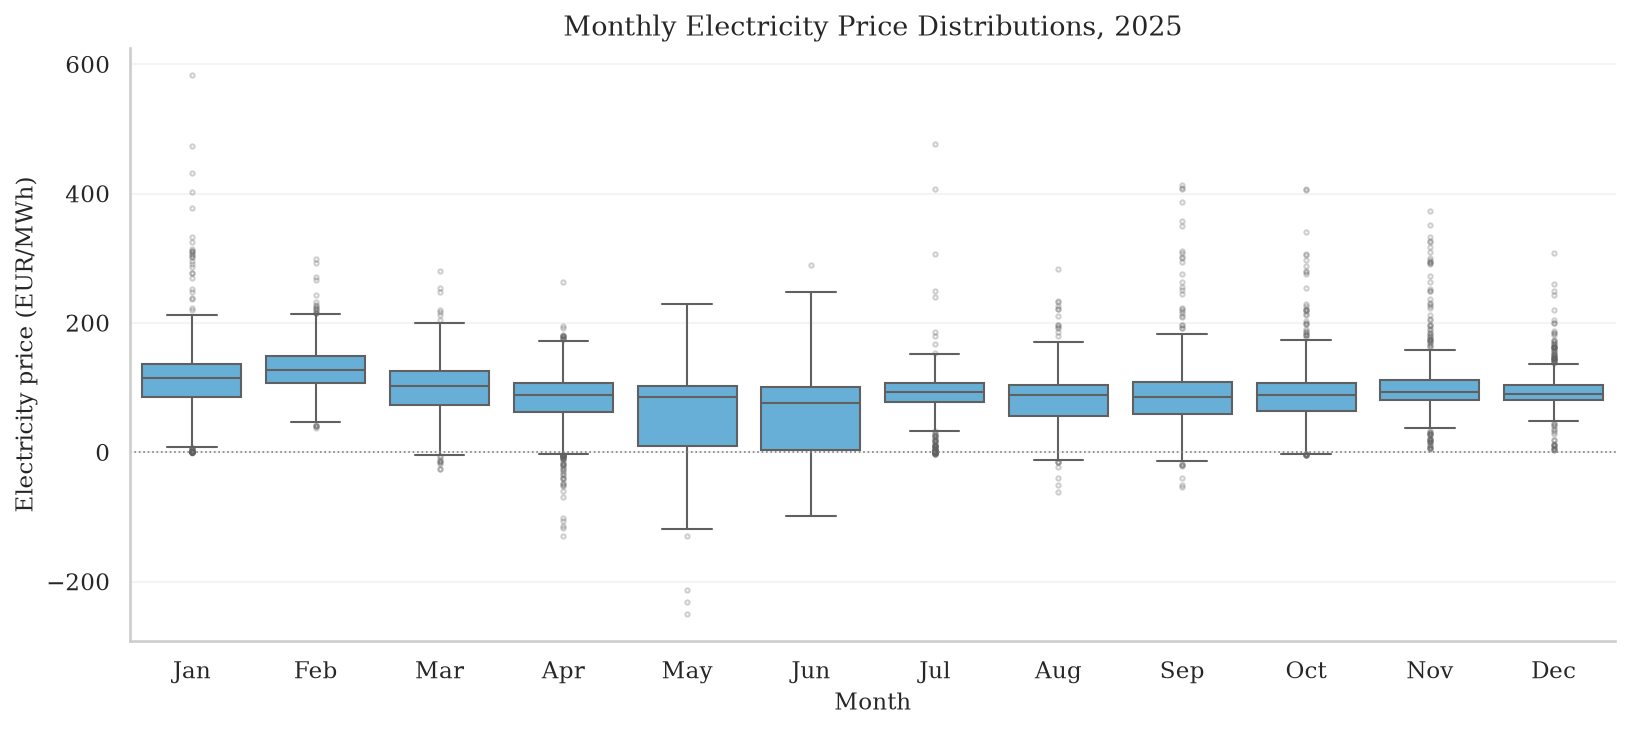

In [13]:
# Calculate monthly descriptive statistics
monthly_summary = (
    eda.groupby("month_name", observed=True)
    ["price_eur_mwh"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

monthly_summary["Negative-price hours"] = (
    eda.groupby("month_name", observed=True)
    ["price_eur_mwh"]
    .apply(lambda x: (x < 0).sum())
)

display(monthly_summary.round(2))

# Create monthly boxplots
fig, ax = plt.subplots(figsize=(11, 5))

sns.boxplot(
    data=eda,
    x="month_name",
    y="price_eur_mwh",
    order=month_order,
    color="#56B4E9",
    flierprops={
        "markersize": 2,
        "alpha": 0.3
    },
    ax=ax
)

ax.axhline(
    0,
    linestyle=":",
    color="grey",
    linewidth=0.8
)

ax.set_title(
    "Monthly Electricity Price Distributions, 2025"
)

ax.set_xlabel("Month")
ax.set_ylabel("Electricity price (EUR/MWh)")

fig.tight_layout()

save_figure(fig, "03_monthly_price_distributions")

monthly_summary.to_csv(
    tables_dir / "monthly_price_summary.csv"
)

plt.show()

## 7. Daily Electricity Price Spreads

Daily price spreads are calculated as the difference
between the maximum and minimum hourly electricity
price within each local calendar day.

This indicator measures the gross price opportunity
associated with shifting electricity consumption
between different hours of the same day.

It does not account for vehicle availability, charging
power, battery constraints or retail tariffs and
therefore does not represent achievable charging savings.

Days containing 23 or 25 hours due to daylight-saving
transitions are retained.

In [14]:
# Calculate daily price statistics
daily_spreads = (
    eda.groupby("date")
    .agg(
        minimum_price=("price_eur_mwh", "min"),
        maximum_price=("price_eur_mwh", "max"),
        average_price=("price_eur_mwh", "mean"),
        observations=("price_eur_mwh", "count"),
        season=("season", "first")
    )
    .reset_index()
)

# Calculate daily price spreads
daily_spreads["spread_eur_mwh"] = (
    daily_spreads["maximum_price"]
    - daily_spreads["minimum_price"]
)

daily_spreads["spread_ct_kwh"] = (
    daily_spreads["spread_eur_mwh"] / 10
)

# Validate daily coverage
assert len(daily_spreads) == 365
assert daily_spreads["observations"].sum() == 8760

assert daily_spreads["observations"].isin(
    [23, 24, 25]
).all()

# Display descriptive statistics
display(
    daily_spreads["spread_ct_kwh"]
    .describe()
    .round(2)
)

# Export daily results
daily_spreads.to_csv(
    tables_dir / "daily_price_spreads.csv",
    index=False
)

count    365.00
mean      12.41
std        6.98
min        0.58
25%        7.47
50%       11.25
75%       15.92
max       46.90
Name: spread_ct_kwh, dtype: float64

#### 7.1 Seasonal comparison of daily price spread

,days,mean,median,std,minimum,maximum
season,,,,,,
Winter,90,8.44,7.49,5.88,1.11,46.90
Spring,92,15.06,14.92,5.72,4.36,37.52
Summer,92,13.88,12.61,5.88,4.49,43.37
Autumn,91,12.19,9.81,8.34,0.58,40.92


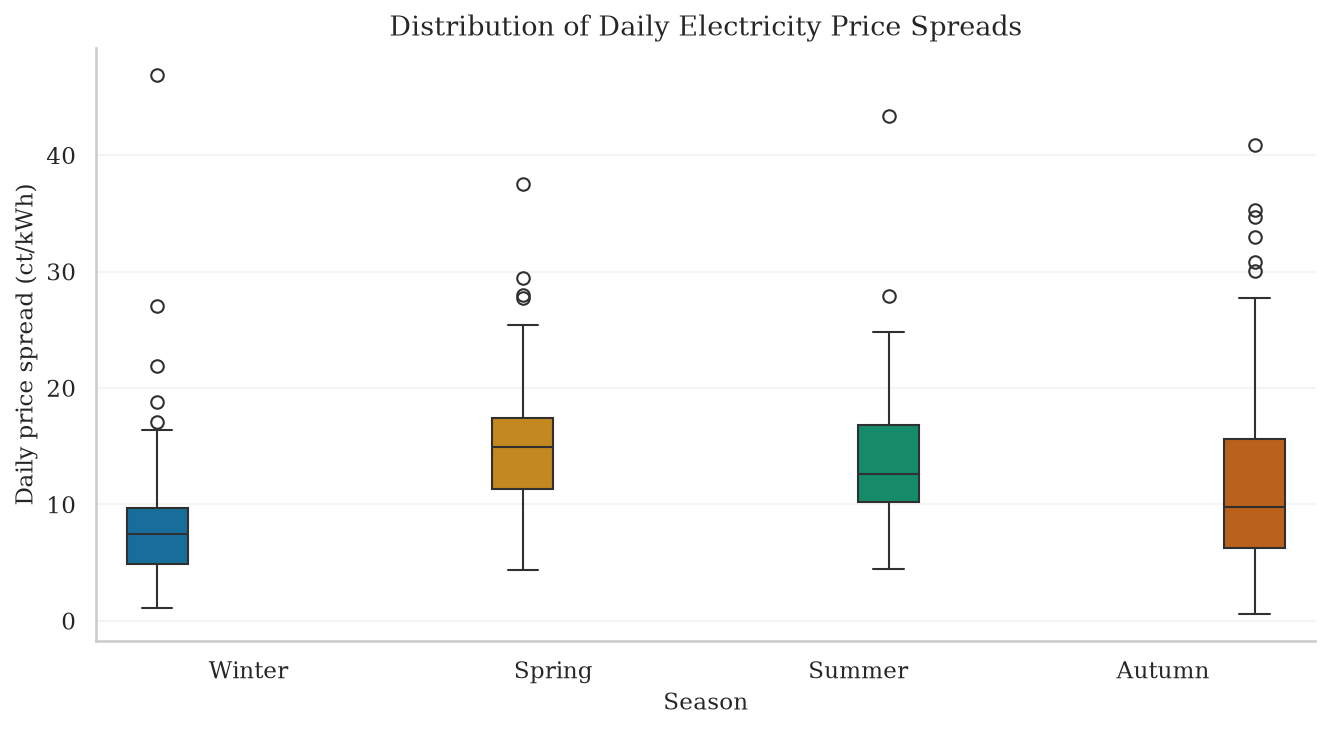

In [15]:
# Summarise daily spreads by season
seasonal_spreads = (
    daily_spreads
    .groupby("season", observed=True)
    ["spread_ct_kwh"]
    .agg(
        days="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .reindex(season_order)
)

display(seasonal_spreads.round(2))

# Create seasonal boxplots
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=daily_spreads,
    x="season",
    y="spread_ct_kwh",
    hue="season",
    order=season_order,
    palette=season_colors,
    legend=False,
    ax=ax
)

ax.set_title(
    "Distribution of Daily Electricity Price Spreads"
)

ax.set_xlabel("Season")
ax.set_ylabel("Daily price spread (ct/kWh)")

fig.tight_layout()

save_figure(fig, "04_daily_price_spreads")

seasonal_spreads.to_csv(
    tables_dir / "seasonal_daily_spreads.csv"
)

plt.show()

## 8. Distribution of Cheapest Charging Hours

The cheapest electricity price period is identified
for each local calendar day.

The objective is to investigate how frequently
different hours offer the lowest electricity price
and whether these opportunities are compatible
with overnight home charging availability.

When multiple hourly observations share the same
minimum price, each receives an equal fractional
weight so that each day contributes a total weight
of one.

This analysis represents electricity market
opportunities rather than feasible EV charging
schedules.

In [16]:
# Identify minimum price on each day
daily_minimum = (
    eda.groupby("date")["price_eur_mwh"]
    .transform("min")
)

# Retain all equally cheapest observations
cheapest_hours = eda.loc[
    eda["price_eur_mwh"].eq(daily_minimum)
].copy()

# Assign equal weights in case of tied minimum prices
cheapest_hours["weight"] = (
    1 / cheapest_hours.groupby("date")["hour"]
    .transform("count")
)

# Verify that every day contributes one unit
assert np.isclose(
    cheapest_hours["weight"].sum(),
    365
)

# Calculate frequency by season and hour
cheapest_hour_distribution = (
    cheapest_hours
    .groupby(
        ["season", "hour"],
        observed=True
    )["weight"]
    .sum()
    .unstack("hour", fill_value=0)
    .reindex(
        index=season_order,
        columns=range(24),
        fill_value=0
    )
)

# Convert counts into seasonal percentages
cheapest_hour_distribution_pct = (
    cheapest_hour_distribution.div(
        cheapest_hour_distribution.sum(axis=1),
        axis=0
    ) * 100
)

display(
    cheapest_hour_distribution_pct.round(2)
)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
season,,,,,,,,,,,,,,,,,,,,,
Winter,4.44,6.67,5.56,28.89,8.89,0.0,3.33,0.0,0.0,0.0,...,2.22,0.00,0.00,0.0,0.0,0.0,0.0,0.0,1.11,18.89
Spring,0.00,1.09,0.00,4.35,0.00,0.0,0.00,0.0,0.0,0.0,...,25.54,3.80,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00
Summer,0.00,1.09,0.00,1.09,0.00,0.0,0.00,0.0,0.0,0.0,...,43.21,8.06,2.17,0.0,0.0,0.0,0.0,0.0,0.00,0.00
Autumn,0.00,3.30,4.40,18.68,4.40,0.0,3.30,1.1,0.0,0.0,...,14.10,1.47,0.00,0.0,0.0,0.0,0.0,0.0,0.00,12.09


#### 8.1 Visualise the distribution

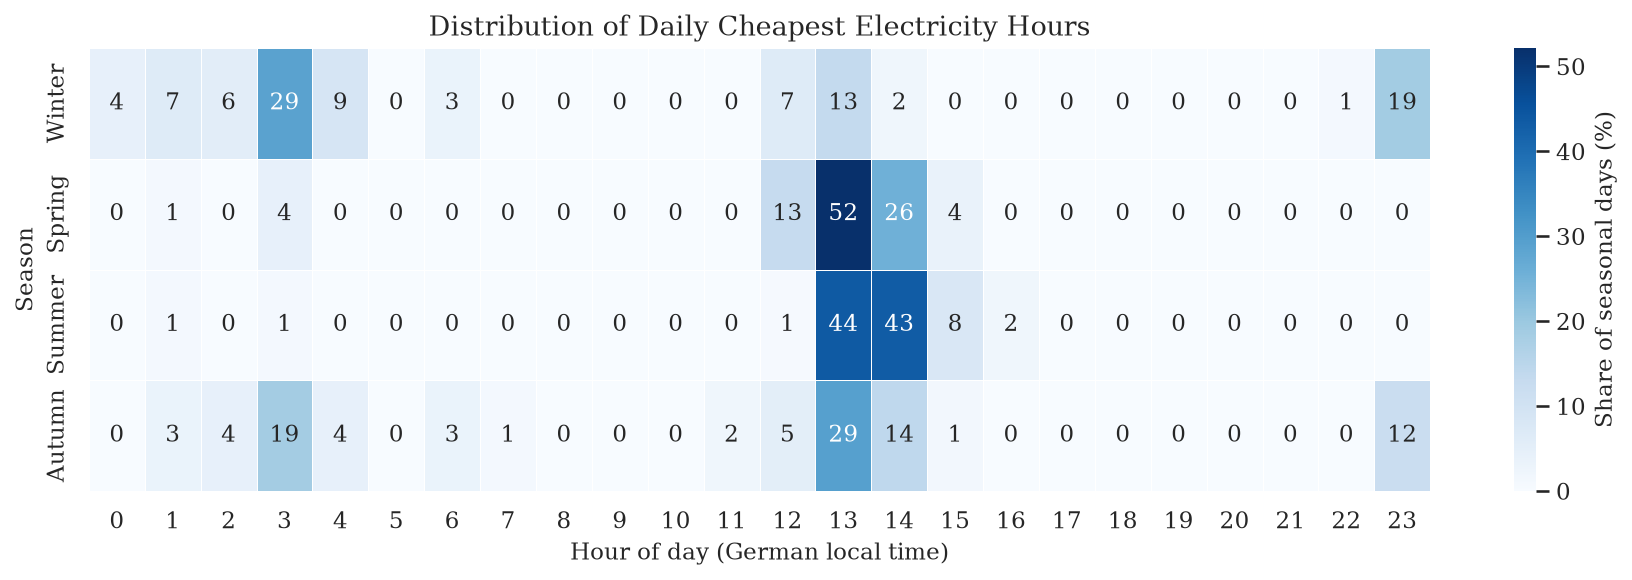

In [17]:
fig, ax = plt.subplots(figsize=(12, 4))

sns.heatmap(
    cheapest_hour_distribution_pct,
    cmap="Blues",
    annot=True,
    fmt=".0f",
    linewidths=0.4,
    cbar_kws={
        "label": "Share of seasonal days (%)"
    },
    ax=ax
)

ax.set_title(
    "Distribution of Daily Cheapest Electricity Hours"
)

ax.set_xlabel("Hour of day (German local time)")
ax.set_ylabel("Season")

ax.set_xticklabels(
    range(24),
    rotation=0
)

fig.tight_layout()

save_figure(
    fig,
    "05_cheapest_hour_distribution"
)

cheapest_hour_distribution_pct.to_csv(
    tables_dir / "cheapest_hour_distribution.csv"
)

plt.show()

#### 8.2 Charging availability and missed opportunities

In [18]:
# Identify cheapest hours within overnight window
cheapest_hours["overnight"] = (
    (cheapest_hours["hour"] >= 18)
    | (cheapest_hours["hour"] < 6)
)

# Weight the corresponding opportunities
cheapest_hours["overnight_weight"] = (
    cheapest_hours["weight"]
    * cheapest_hours["overnight"]
)

# Calculate seasonal opportunity shares
availability_summary = (
    cheapest_hours
    .groupby("season", observed=True)
    .agg(
        total_weight=("weight", "sum"),
        overnight_weight=("overnight_weight", "sum")
    )
    .reindex(season_order)
)

availability_summary["Overnight share (%)"] = (
    availability_summary["overnight_weight"]
    / availability_summary["total_weight"]
    * 100
)

availability_summary["Daytime share (%)"] = (
    100 - availability_summary["Overnight share (%)"]
)

display(
    availability_summary[
        ["Overnight share (%)", "Daytime share (%)"]
    ].round(2)
)

availability_summary.to_csv(
    tables_dir / "charging_availability_opportunities.csv"
)

,Overnight share (%),Daytime share (%)
season,,
Winter,74.44,25.56
Spring,5.43,94.57
Summer,2.17,97.83
Autumn,42.86,57.14


#### 8.3 Visualise the availability trade-off

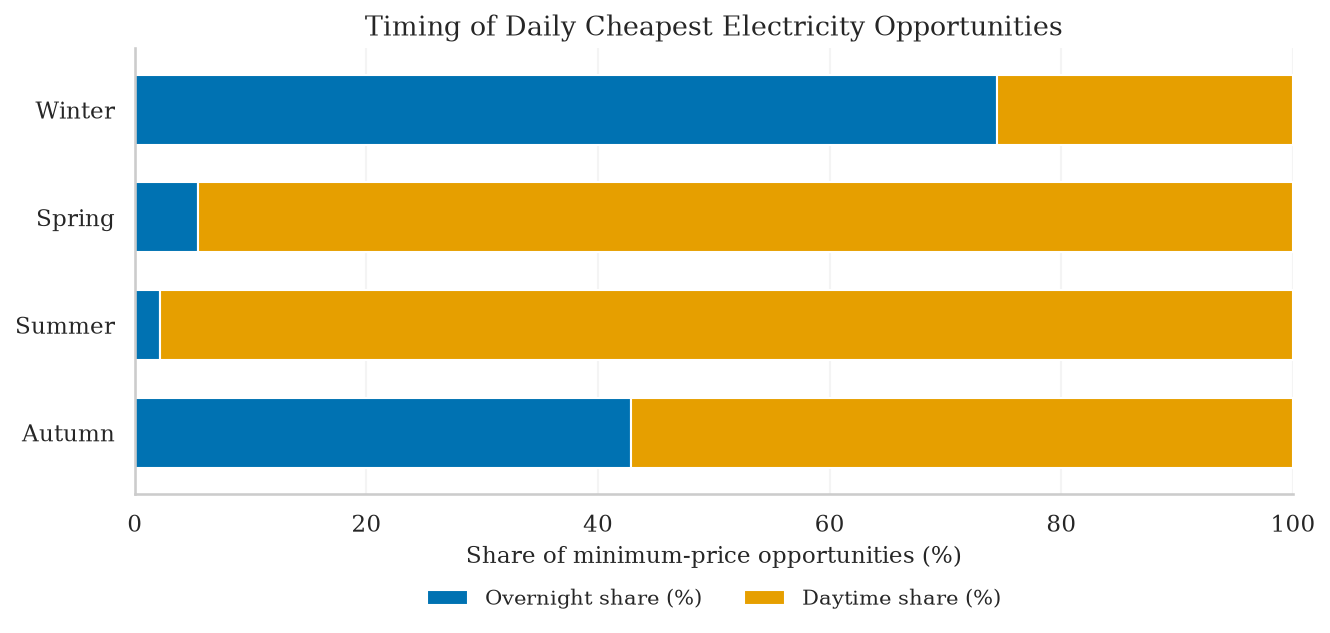

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))

availability_summary[
    ["Overnight share (%)", "Daytime share (%)"]
].plot(
    kind="barh",
    stacked=True,
    color=["#0072B2", "#E69F00"],
    width=0.65,
    ax=ax
)

ax.set_title(
    "Timing of Daily Cheapest Electricity Opportunities"
)

ax.set_xlabel("Share of minimum-price opportunities (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.invert_yaxis()

ax.legend(
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.30),
    ncol=2
)

fig.tight_layout()

save_figure(
    fig,
    "06_charging_availability_opportunities"
)

plt.show()

## 9. Economic Interpretation and Key Findings

### 9.1 Electricity Price Variability

The validated dataset comprises 8,760 hourly electricity price observations for the Germany–Luxembourg day-ahead market in 2025.

The annual average electricity price amounts to 89.32 EUR/MWh, with a standard deviation of 52.10 EUR/MWh. Hourly prices range from −250.32 EUR/MWh to 583.40 EUR/MWh, demonstrating substantial temporal price variability.

However, annual price extremes do not directly represent feasible smart-charging opportunities, since electricity consumption cannot be shifted arbitrarily across the year. Intraday price variability is therefore more relevant to the economic assessment of EV charging strategies.

### 9.2 Seasonal Price Dynamics

Seasonal average hourly price profiles reveal considerable differences in the timing of economically attractive electricity consumption.

| Season | Cheapest average hour | Minimum average price (EUR/MWh) | Profile spread (ct/kWh) |
|---|---:|---:|---:|
| Winter | 03:00 | 84.14 | 6.39 |
| Spring | 13:00 | 7.58 | 13.34 |
| Summer | 14:00 | 13.11 | 12.86 |
| Autumn | 13:00 | 61.03 | 9.29 |

While the cheapest average electricity hour occurs during the night in winter, the corresponding hours occur during the early afternoon in the remaining seasons.

These results suggest that a fixed nighttime charging strategy may not consistently align with the most economically attractive electricity market conditions throughout the year.

### 9.3 Daily Electricity Price Spreads

The analysis of daily maximum–minimum price spreads provides further evidence of seasonal differences in gross economic opportunities.

| Season | Mean daily spread (ct/kWh) | Median daily spread (ct/kWh) |
|---|---:|---:|
| Winter | 8.44 | 7.49 |
| Spring | 15.06 | 14.92 |
| Summer | 13.88 | 12.61 |
| Autumn | 12.19 | 9.81 |

The mean daily price spread is approximately 78.4% higher in spring than in winter.

Furthermore, autumn exhibits the highest standard deviation of daily price spreads (8.34 ct/kWh), indicating substantial variation in the magnitude of daily price opportunities.

These findings motivate the investigation of dynamic charging strategies that respond to individual daily electricity prices rather than exclusively relying on predetermined charging schedules.

### 9.4 Temporal Alignment of Charging Flexibility

The distribution of daily minimum-price opportunities reveals a pronounced seasonal shift between nighttime and daytime hours.

| Season | Overnight share (%) | Daytime share (%) |
|---|---:|---:|
| Winter | 74.44 | 25.56 |
| Spring | 5.43 | 94.57 |
| Summer | 2.17 | 97.83 |
| Autumn | 42.86 | 57.14 |

Overnight availability is defined as 18:00–06:00, while daytime availability is defined as 06:00–18:00. Tied daily minimum prices are assigned fractional weights.

Although both availability windows have the same nominal duration, their alignment with daily minimum-price opportunities differs substantially across seasons.

This suggests that the economic potential of charging flexibility depends not only on its duration but also on its temporal alignment with electricity market dynamics.

### 9.5 Implications for the Charging Simulation

The exploratory findings motivate three subsequent investigations:

1. A comparison of immediate, fixed-time and dynamic charging strategies.
2. An assessment of the marginal economic value of additional charging availability.
3. A comparison of equally long charging windows occurring at different times of the day.

These investigations will determine whether the observed electricity market opportunities translate into meaningful charging cost reductions under explicit technical and mobility constraints.

### 9.6 Limitations

The exploratory analysis measures electricity market opportunities rather than achievable EV charging savings.

Daily price spreads do not incorporate battery capacity, charging power, energy requirements, vehicle availability or retail electricity tariff structures.

Furthermore, minimum-price opportunity shares do not quantify the financial consequences of missing individual low-price periods. Alternative feasible charging hours may offer similar prices.

The analysis is restricted to one bidding zone and one calendar year. The findings therefore cannot automatically be generalised to other electricity markets or future market conditions.

The causal determinants of the observed seasonal price patterns are not explicitly investigated.

**Source:** Own calculations based on historical Germany–Luxembourg day-ahead electricity prices for 2025, retrieved from the Fraunhofer ISE Energy-Charts API and validated against Bundesnetzagentur SMARD statistics.

In [20]:
# Consolidate key exploratory findings

eda_summary = pd.DataFrame({
    "Cheapest average hour":
        seasonal_summary["Cheapest hour"],

    "Minimum average price (EUR/MWh)":
        seasonal_summary["Lowest average price (EUR/MWh)"],

    "Average profile spread (ct/kWh)":
        seasonal_summary["Profile spread (ct/kWh)"],

    "Mean daily spread (ct/kWh)":
        seasonal_spreads["mean"],

    "Median daily spread (ct/kWh)":
        seasonal_spreads["median"],

    "Std. daily spread (ct/kWh)":
        seasonal_spreads["std"],

    "Overnight opportunity share (%)":
        availability_summary["Overnight share (%)"],

    "Daytime opportunity share (%)":
        availability_summary["Daytime share (%)"]
}).reindex(season_order)

# Verify consistency
assert eda_summary.notna().all().all()

assert np.allclose(
    eda_summary["Overnight opportunity share (%)"]
    + eda_summary["Daytime opportunity share (%)"],
    100
)

# Display consolidated findings
display(eda_summary.round(2))

# Export summary
eda_summary.to_csv(
    tables_dir / "eda_consolidated_findings.csv"
)

print("Exploratory data analysis completed.")
print("Consolidated findings successfully exported.")

,Cheapest average hour,Minimum average price (EUR/MWh),Average profile spread (ct/kWh),Mean daily spread (ct/kWh),Median daily spread (ct/kWh),Std. daily spread (ct/kWh),Overnight opportunity share (%),Daytime opportunity share (%)
season,,,,,,,,
Winter,3,84.14,6.39,8.44,7.49,5.88,74.44,25.56
Spring,13,7.58,13.34,15.06,14.92,5.72,5.43,94.57
Summer,14,13.11,12.86,13.88,12.61,5.88,2.17,97.83
Autumn,13,61.03,9.29,12.19,9.81,8.34,42.86,57.14


Exploratory data analysis completed.
Consolidated findings successfully exported.
